In [1]:
import numpy as np 

def build_heatmap(coords, scores, weights, patch_size=512, scale_factor=16, save_path=None):
    """
    coords: Nx2 array (x, y)
    scores: N array con valores 0,1,2,3
    weights: N array con intensidad (ej. 0–1 o cualquier rango)
    Produce heatmap en RGB con colores por clase modulados por la intensidad.
    """

    # Escalar coordenadas
    coords = coords // scale_factor
    patch_size = patch_size // scale_factor

    max_x, max_y = coords[:, 0].max(), coords[:, 1].max()
    min_x, min_y = coords[:, 0].min(), coords[:, 1].min()

    width  = max_x - min_x + 1
    height = max_y - min_y + 1

    # Ajustar coordenadas
    shifted_coords = coords.copy()
    shifted_coords[:, 0] -= min_x
    shifted_coords[:, 1] -= min_y

    # Heatmap RGB
    heatmap = np.zeros((height + patch_size, width + patch_size, 3), dtype=np.uint8)

    # Colores base
    color_map = {
        3: np.array([255,   0,   0]),  # Rojo
        2: np.array([255, 128,   0]),  # Naranja
        1: np.array([255, 255,   0]),  # Amarillo
        0: np.array([  0,   0, 255])   # Azul
    }

    # Dibujar los parches modulando por el peso
    for (x, y), s, w in zip(shifted_coords, scores, weights):

        base_color = color_map.get(int(s), np.array([255, 255, 255]))
        
        # Normalizar peso si viene fuera de 0–1
        # w_norm = (w - weights.min()) / (weights.max() - weights.min())
        w_norm = float(w)*10

        # Escalar color por intensidad
        color = (base_color * w_norm).clip(0, 255).astype(np.uint8)

        heatmap[y:y+patch_size, x:x+patch_size] = color

    img = Image.fromarray(heatmap, mode="RGB")

    if save_path:
        img.save(save_path)

    return img


In [2]:
# IMPORT LIBRARIES
import os 
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import pandas as pd 
from accelerate import Accelerator
from safetensors.torch import load_file

current_dir  = os.path.abspath(os.getcwd())# Directorio actual
sys.path.append(os.path.dirname(current_dir))

from utils.data_load import WSI_Dataset, create_file_label_df, collate_fn
from utils.train_utils import run_epoch
from utils.metrics_utils import log_epoch_metrics, save_metrics_to_csv
from utils.heatmap_utils import  overlay_heatmap_on_image, draw_gt_patches

from models.keep_model import get_keep_ia3_model
from models.CNN import CNNEmbedder

# DEFINE PATHS 
ckpt_path = "/workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100"
folder_original_imgs = '/workspace/data/TCGA/stitiches'
num_img_show = 20

sicap_images_folder_path='/workspace/data/TCGA/patches' #'/workspace/data/TCGA/patches'' #'/workspace/data/features_SICAP/patches' 
sicap_labels_df_path=  '/workspace/data/features_PRAD/tcga_dataset.xlsx' #  '/workspace/data/wsi_labels_changed_SICAP.xlsx' #'/workspace/data/features_PRAD/tcga_dataset.xlsx' # 
mask_folder= '/workspace/data/TCGA/stitiches' #"/workspace/data/annotation_masks_SICAP"
# GENERAL CONFIGURATION 
print(" *Starting General Configuration ...")
CUDA_LAUNCH_BLOCKING=1
use_amp = torch.cuda.is_available()  # mixed precision if GPU available

accelerator = Accelerator()
device = accelerator.device
print(f" Usando dispositivo: {device}", flush = True)

# LOADING MODEL 
if "CNN" in ckpt_path:
    print(f"Model: CNN")
    model = CNNEmbedder(clasification_model='graph')
if "KEEP" in ckpt_path:
    print(f"Model: KEEP")
    model = get_keep_ia3_model(clasification_model='mlp', pretrain=False )
    model = torch.nn.SyncBatchNorm.convert_sync_batchnorm(model)

# Cargar pesos
state_dict = load_file(os.path.join(ckpt_path,'best_model', "model.safetensors"), device="cpu")
model.load_state_dict(state_dict, strict=True)
#accelerator.load_state(ckpt_path)
print(" Pesos cargados correctamente")

loss = nn.BCELoss() 

# LOADING DATA
df_test = create_file_label_df(sicap_images_folder_path, sicap_labels_df_path, NAME = 'SICAP')
df_test = df_test.head(10)
label_mapping = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 3}
df_test['gleason_primary_mapped'] = df_test['gleason_primary'].map(label_mapping)
df_test['gleason_secondary_mapped'] = df_test['gleason_secondary'].map(label_mapping)
df_test['gleason_score'] = df_test['gleason_score'].astype(int)

print("Loading embeddings for Inference ...")
inference_loader = DataLoader(WSI_Dataset(df_test, df_test.index, inference_heatmap=True), shuffle=False, batch_size=1, collate_fn=collate_fn)

# INFERENCE IN MODEL
model, inference_loader = accelerator.prepare(model, inference_loader)
inference_metrics, inference_loss, _,_,_,test_outputs = run_epoch(model, inference_loader, device, accelerator, loss, None, 
                                                                mode='test',inference_heatmap=True, multilabel_prob_threshold=0.15, 
                                                                min_presence_threshold=0.2, secondary_ratio_threshold=0.2,alpha_pe=0, alpha_pc=0)   
# METRICS 
print(f"AUROC (Macro): {inference_metrics['multilabel']['auroc_macro']} \n")
print(f"AUROC (Weighted): {inference_metrics['multilabel']['auroc_weighted']} \n")
print(f"AUPRC (Macro): {inference_metrics['multilabel']['auprc_macro']} \n")
print(f"AUPRC (Weighted): {inference_metrics['multilabel']['auprc_weighted']} \n")

log_epoch_metrics("SICAP dataset", "Test", inference_metrics, inference_loss, os.path.join(ckpt_path, "heatmap_inference.txt"))
save_metrics_to_csv(inference_metrics, epoch=0,  filepath= os.path.join(ckpt_path, "heatmap_inference.csv"))


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True   n_gpus: 1
 *Starting General Configuration ...
 Usando dispositivo: cuda
Model: KEEP
Parámetros entrenables: 726565
 Pesos cargados correctamente
Procesando WSIs: 100%|██████████| 19/19 [00:00<00:00, 1387.73it/s]
Loading embeddings for Inference ...
TEST: 100%|██████████| 10/10 [00:14<00:00,  1.48s/it]
AUROC (Macro): nan 

AUROC (Weighted): nan 

AUPRC (Macro): 0.6891953262786596 

AUPRC (Weighted): 0.9159430438842204 


=== Época SICAP dataset | TEST METRICS ===
Loss global: 0.3719

-- PRIMARY --
  Accuracy : 0.7000
  Precision (Micro)   : 0.7000
  Precision (Macro)   : 0.3875
  Precision (Weighted): 0.7050
  Recall (Micro)      : 0.7000
  Recall (Macro)      : 0.4167
  Recall (Weighted)   : 0.7000
  F1 Score (Micro)    : 0.7000
  F1 Score (Macro)    : 0.3961
  F1 Score (Weighted) : 0.6935
  Kappa               : 0.3750

-- SECONDARY --
  Accuracy : 0.5000
  Precision (Micro)   : 0.5000
  Precision (Macro)   : 0.4167
  Precision (Weighted): 0.5833
  Recall (Micr

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:891: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:891: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-CH-5769-01Z-00-DX1.cd4fbd94-7698-43e6-92e7-d6f52888de6a.png 
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-EJ-5499-01Z-00-DX1.bda3d0ed-5295-40c2-b23f-d60caaa03643.png 
slide /workspace/data/TCGA/patches/TCGA-EJ-5499-01Z-00-DX1.bda3d0ed-5295-40c2-b23f-d60caaa03643.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 3.


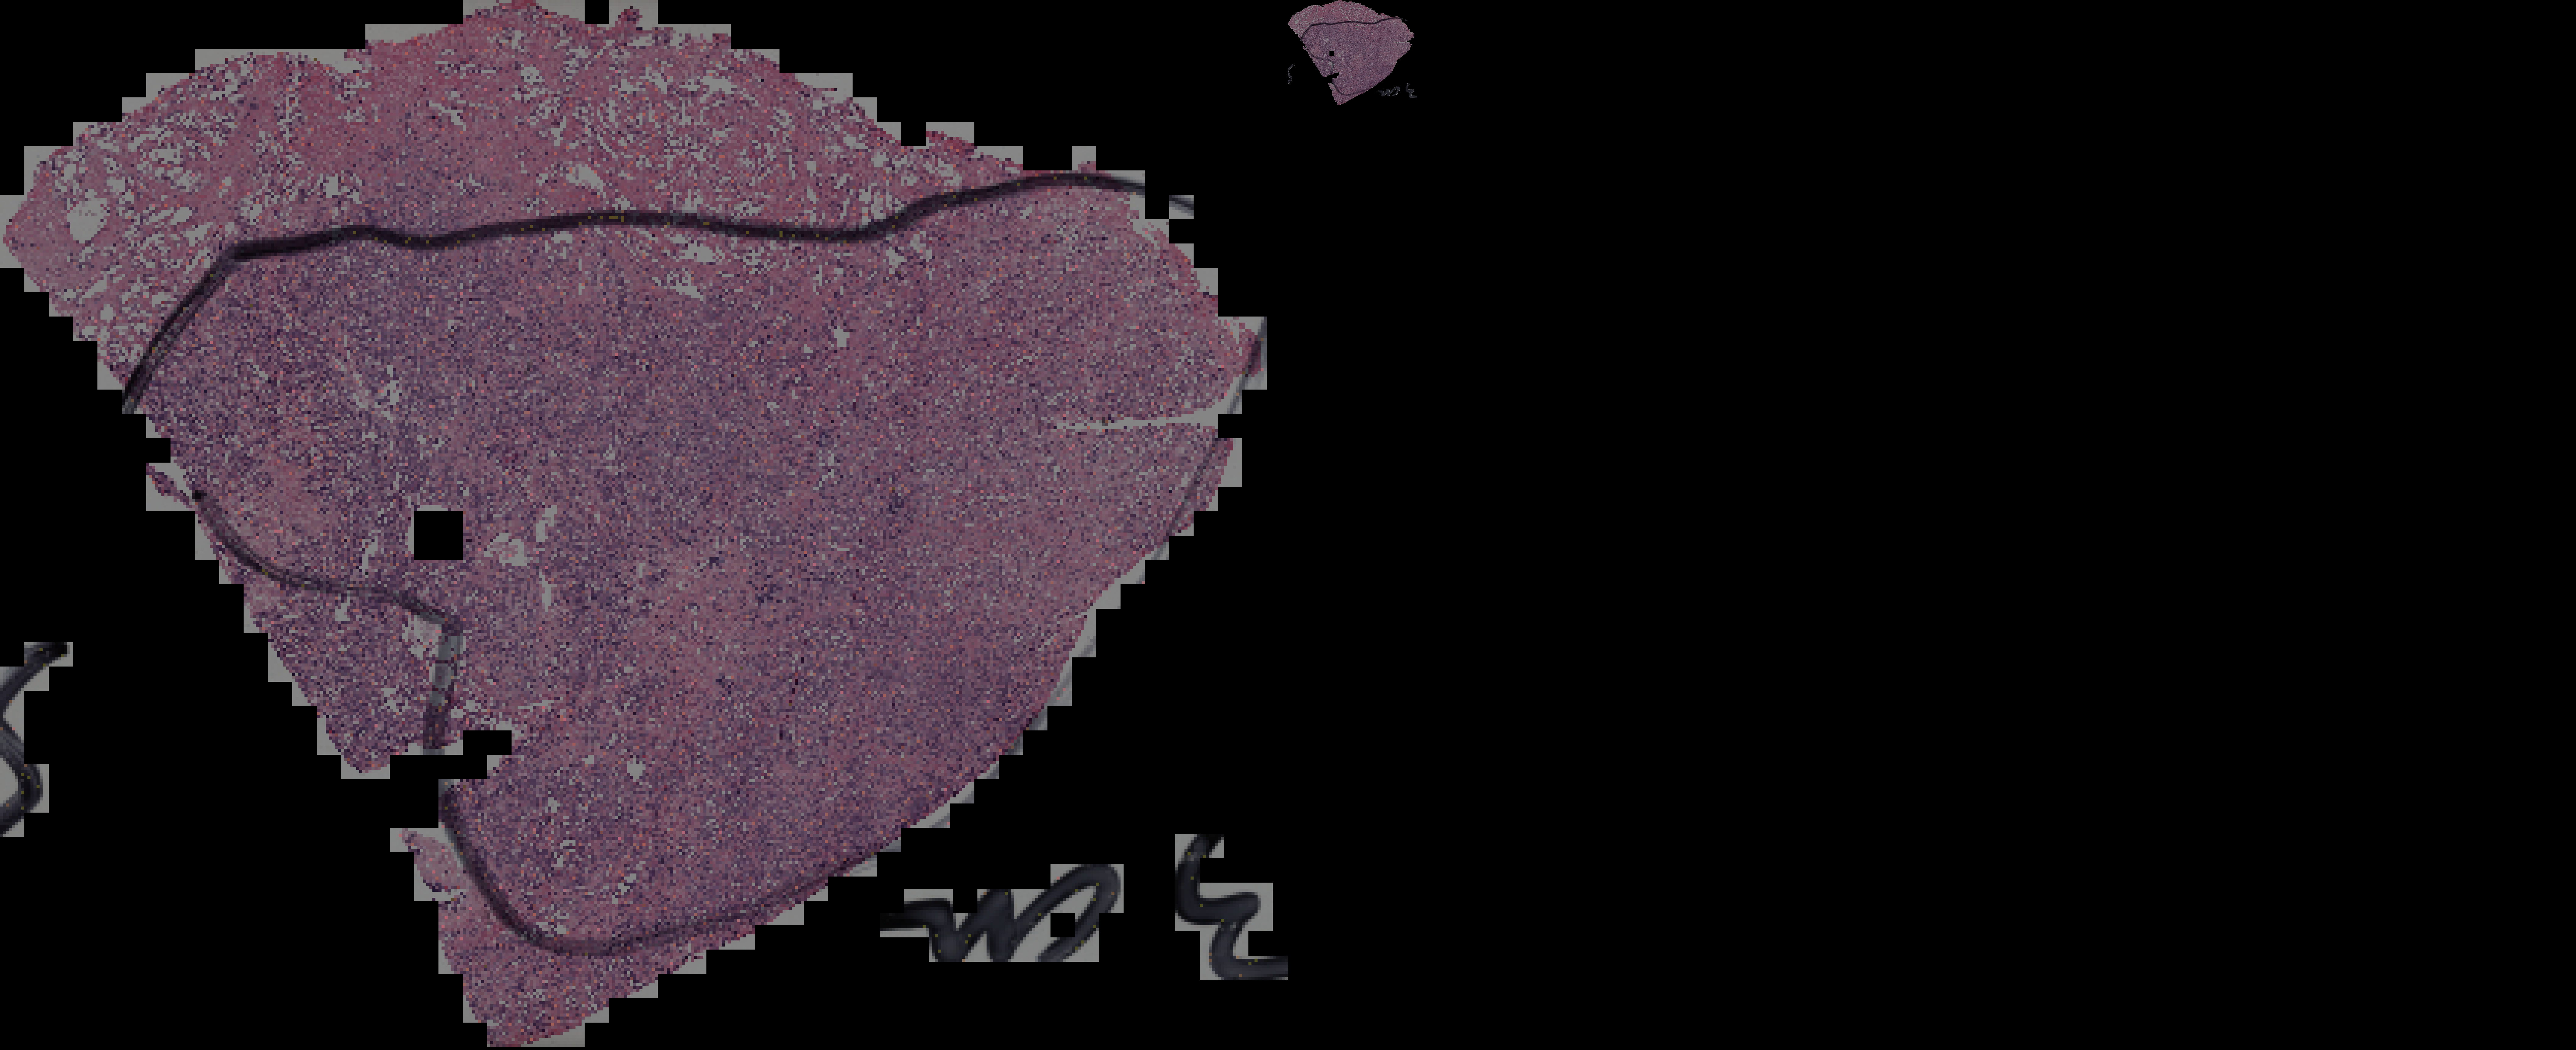

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_TCGA/TCGA-EJ-5499-01Z-00-DX1.bda3d0ed-5295-40c2-b23f-d60caaa03643.png
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-EJ-5511-01Z-00-DX1.45a97ef9-90fb-400d-9bdb-ebe8776e228b.png 
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-EJ-5514-01Z-00-DX1.82b0677b-fb3c-45ec-82ca-d90000d8aaf2.png 
slide /workspace/data/TCGA/patches/TCGA-EJ-5514-01Z-00-DX1.82b0677b-fb3c-45ec-82ca-d90000d8aaf2.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 5.


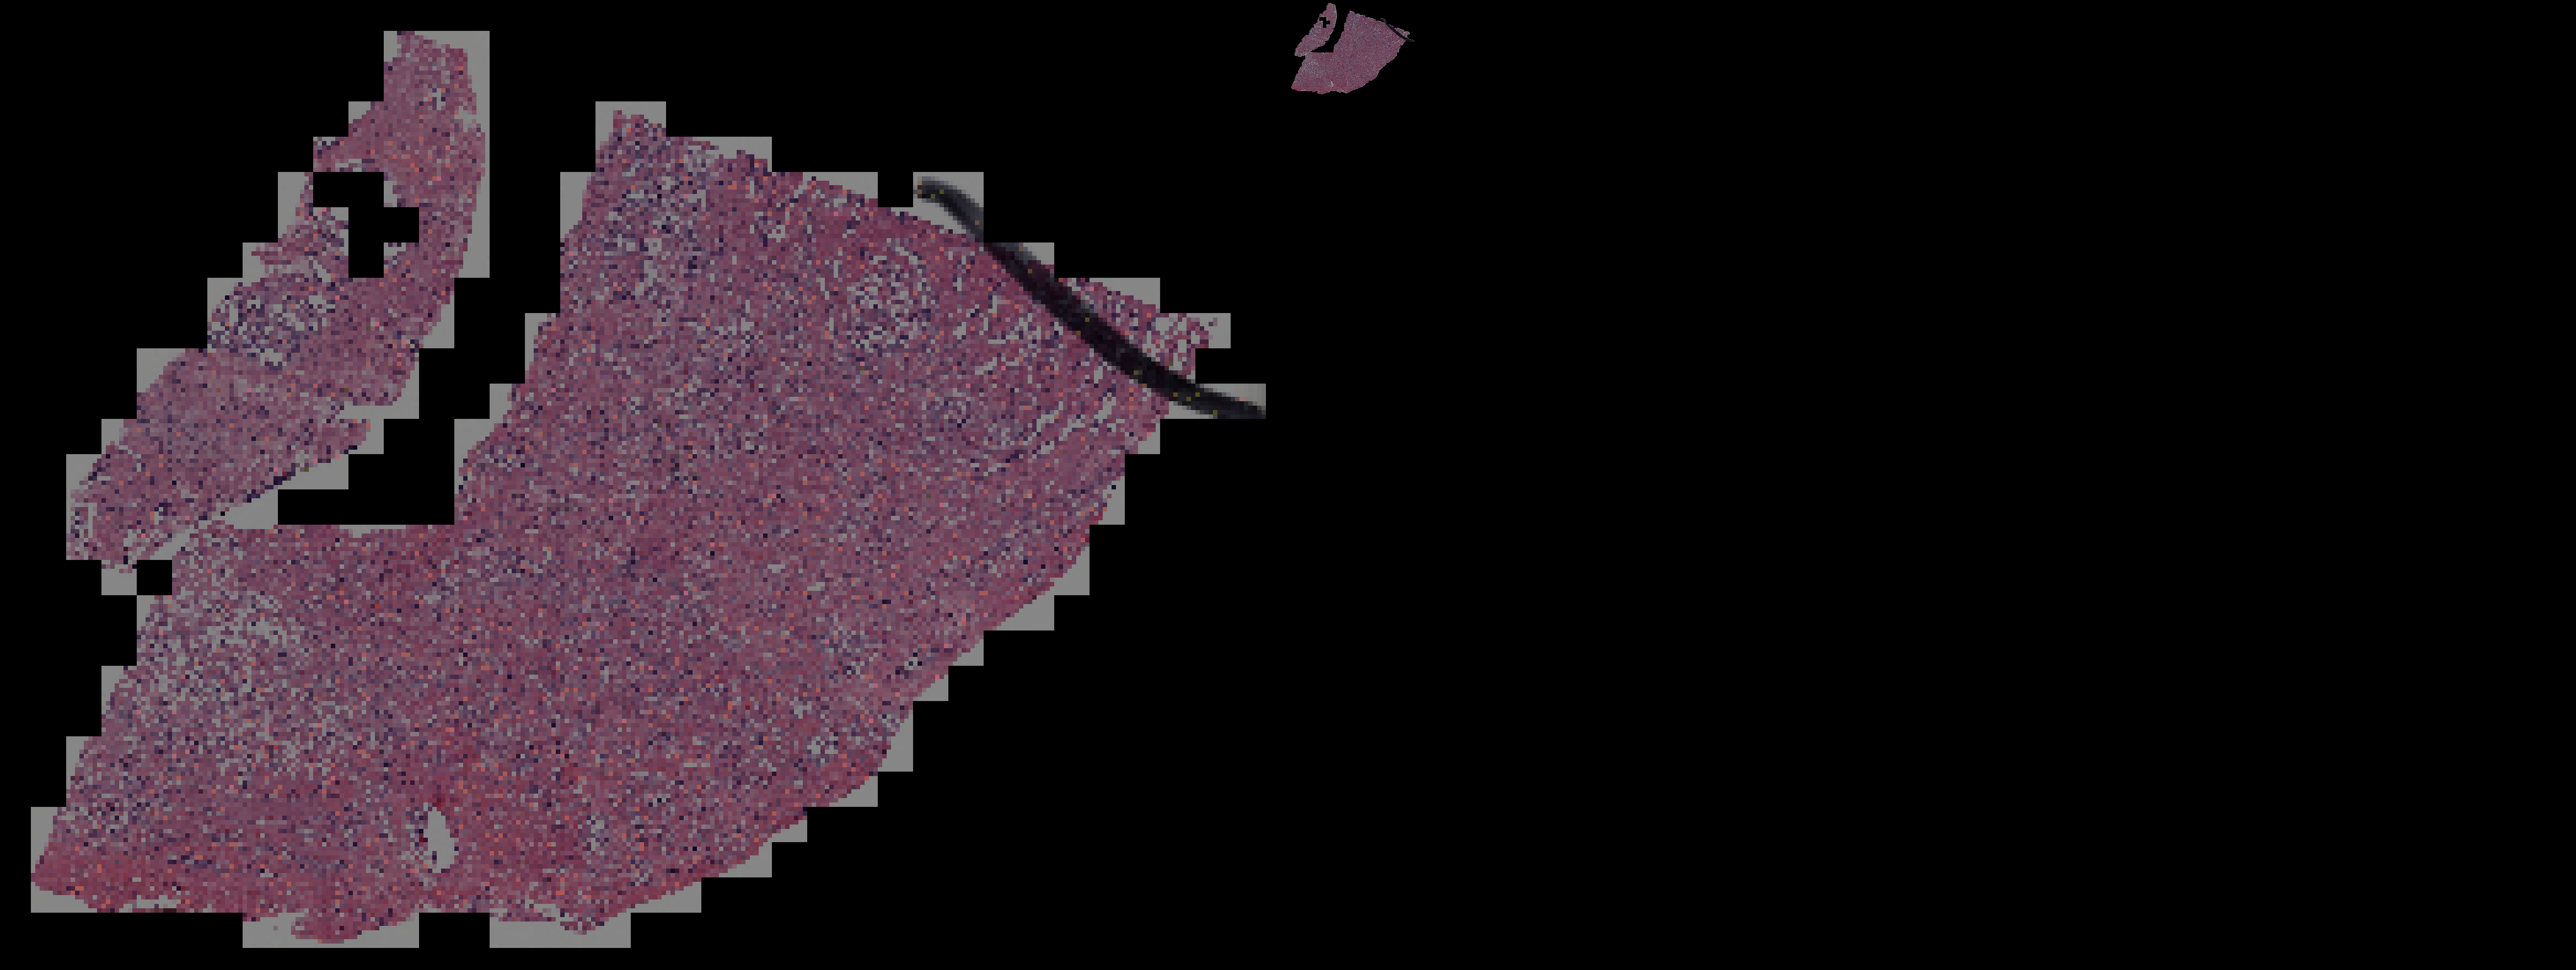

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_TCGA/TCGA-EJ-5514-01Z-00-DX1.82b0677b-fb3c-45ec-82ca-d90000d8aaf2.png
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-EJ-5527-01Z-00-DX1.238fcb19-9655-463e-ab50-b48b71e6970e.png 
slide /workspace/data/TCGA/patches/TCGA-EJ-5527-01Z-00-DX1.238fcb19-9655-463e-ab50-b48b71e6970e.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 3.


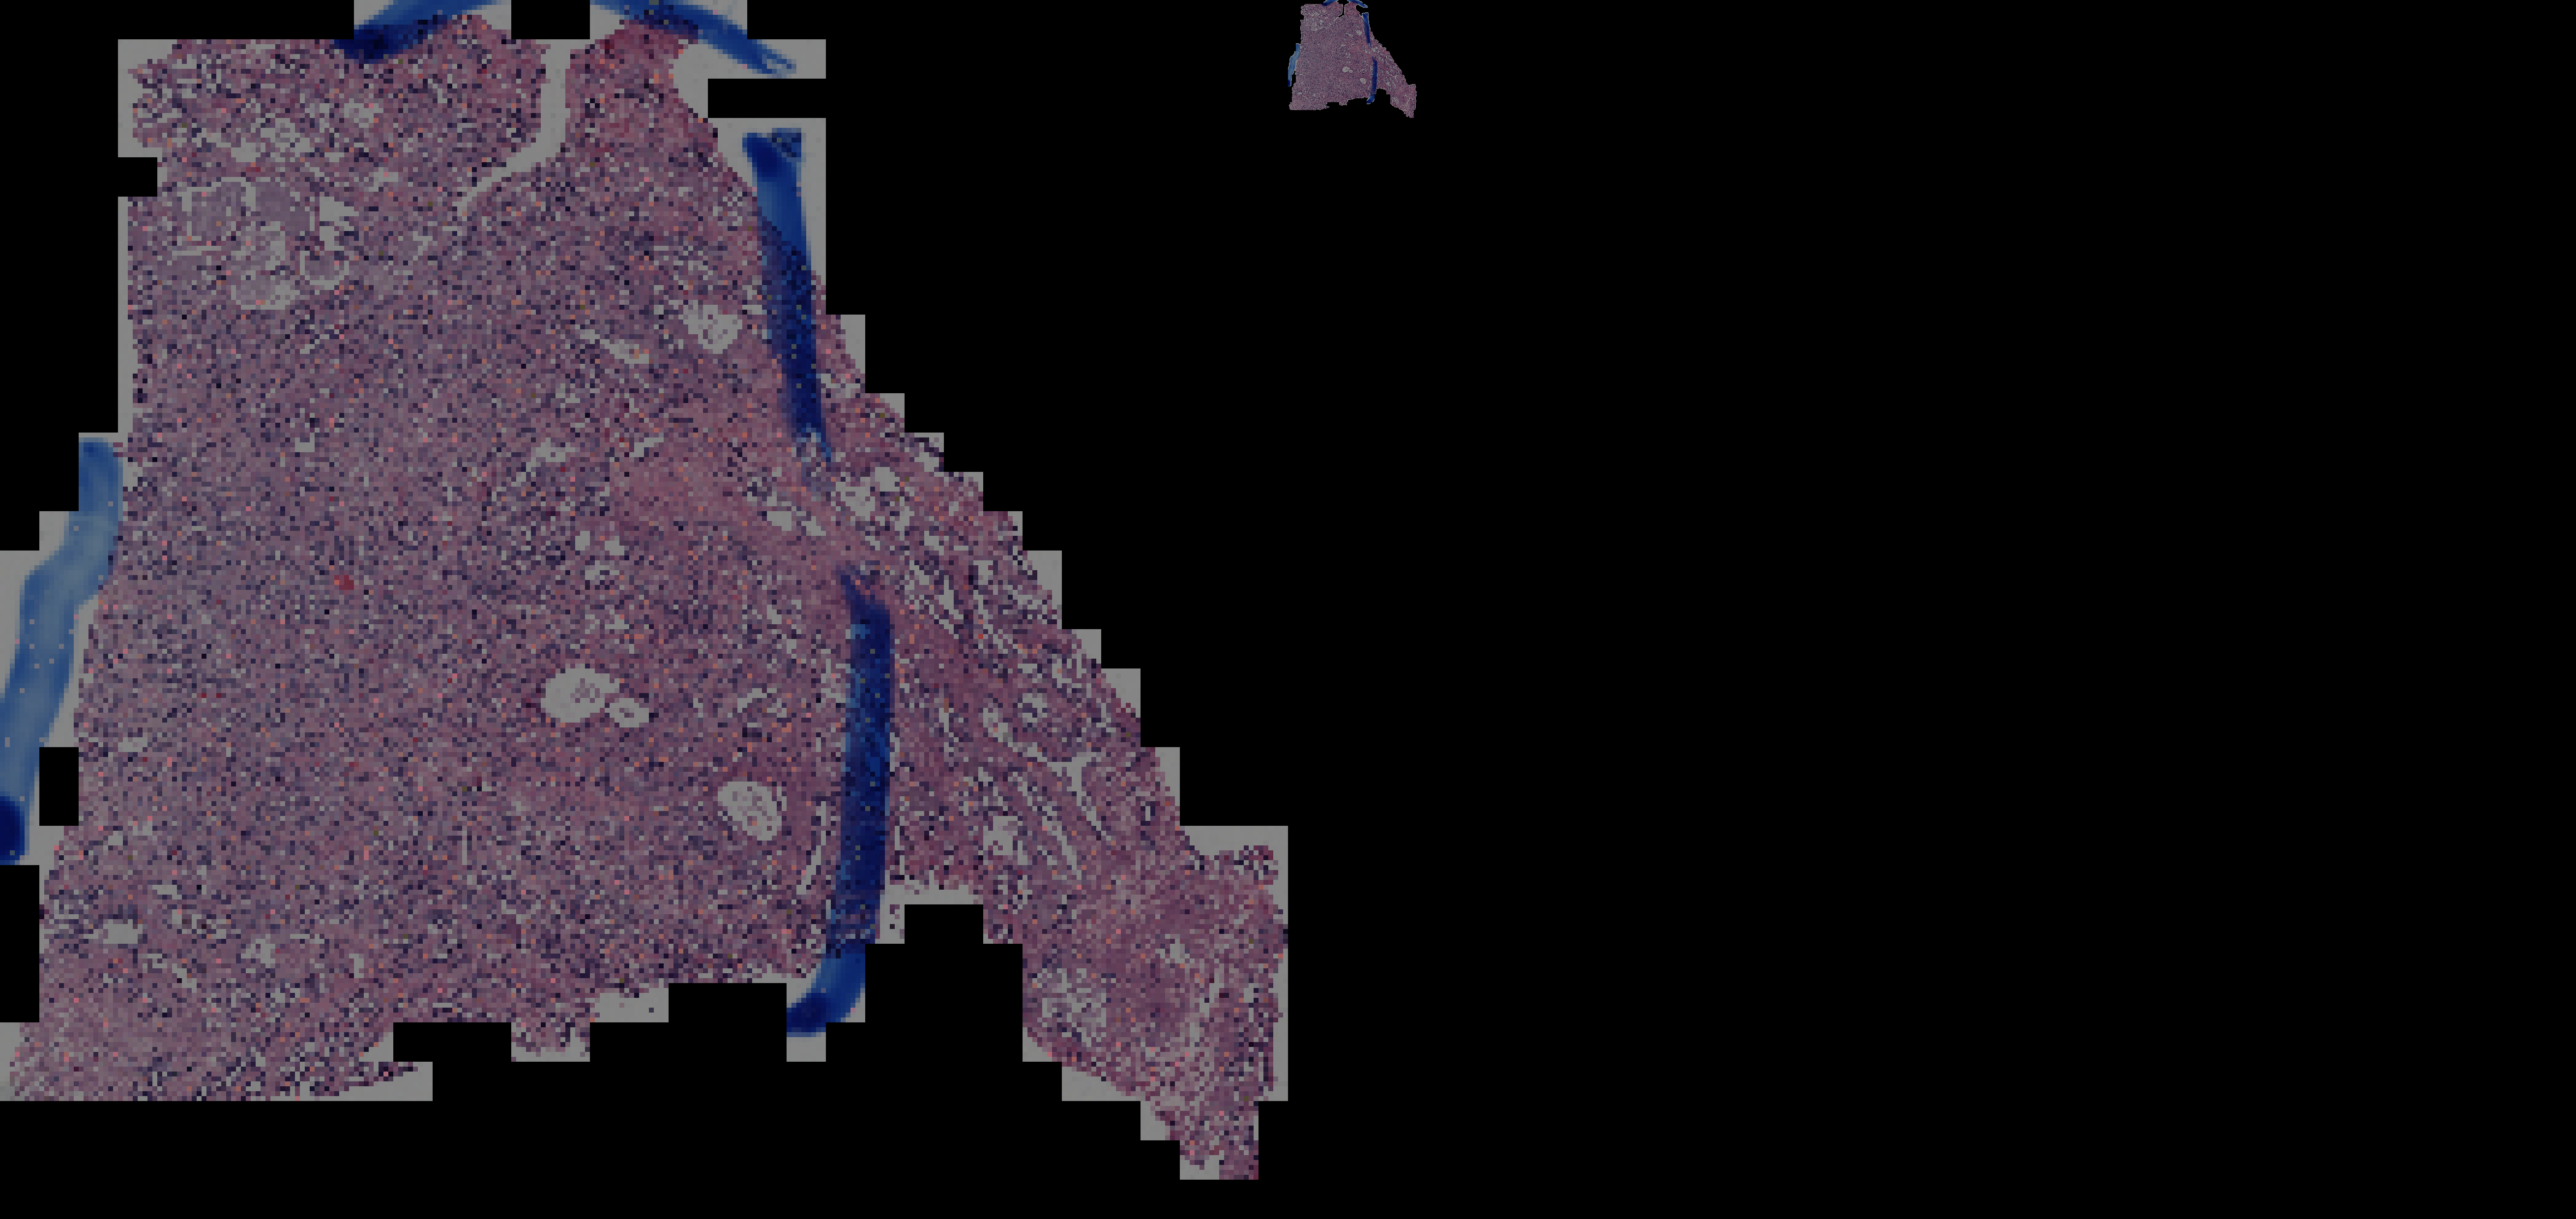

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_TCGA/TCGA-EJ-5527-01Z-00-DX1.238fcb19-9655-463e-ab50-b48b71e6970e.png
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-FC-7961-01Z-00-DX1.9a513f3d-b401-4450-8486-ee04751da4e8.png 
slide /workspace/data/TCGA/patches/TCGA-FC-7961-01Z-00-DX1.9a513f3d-b401-4450-8486-ee04751da4e8.h5
 Scores de la slide: Grado Primario = NC & Grado Secundario = NC.


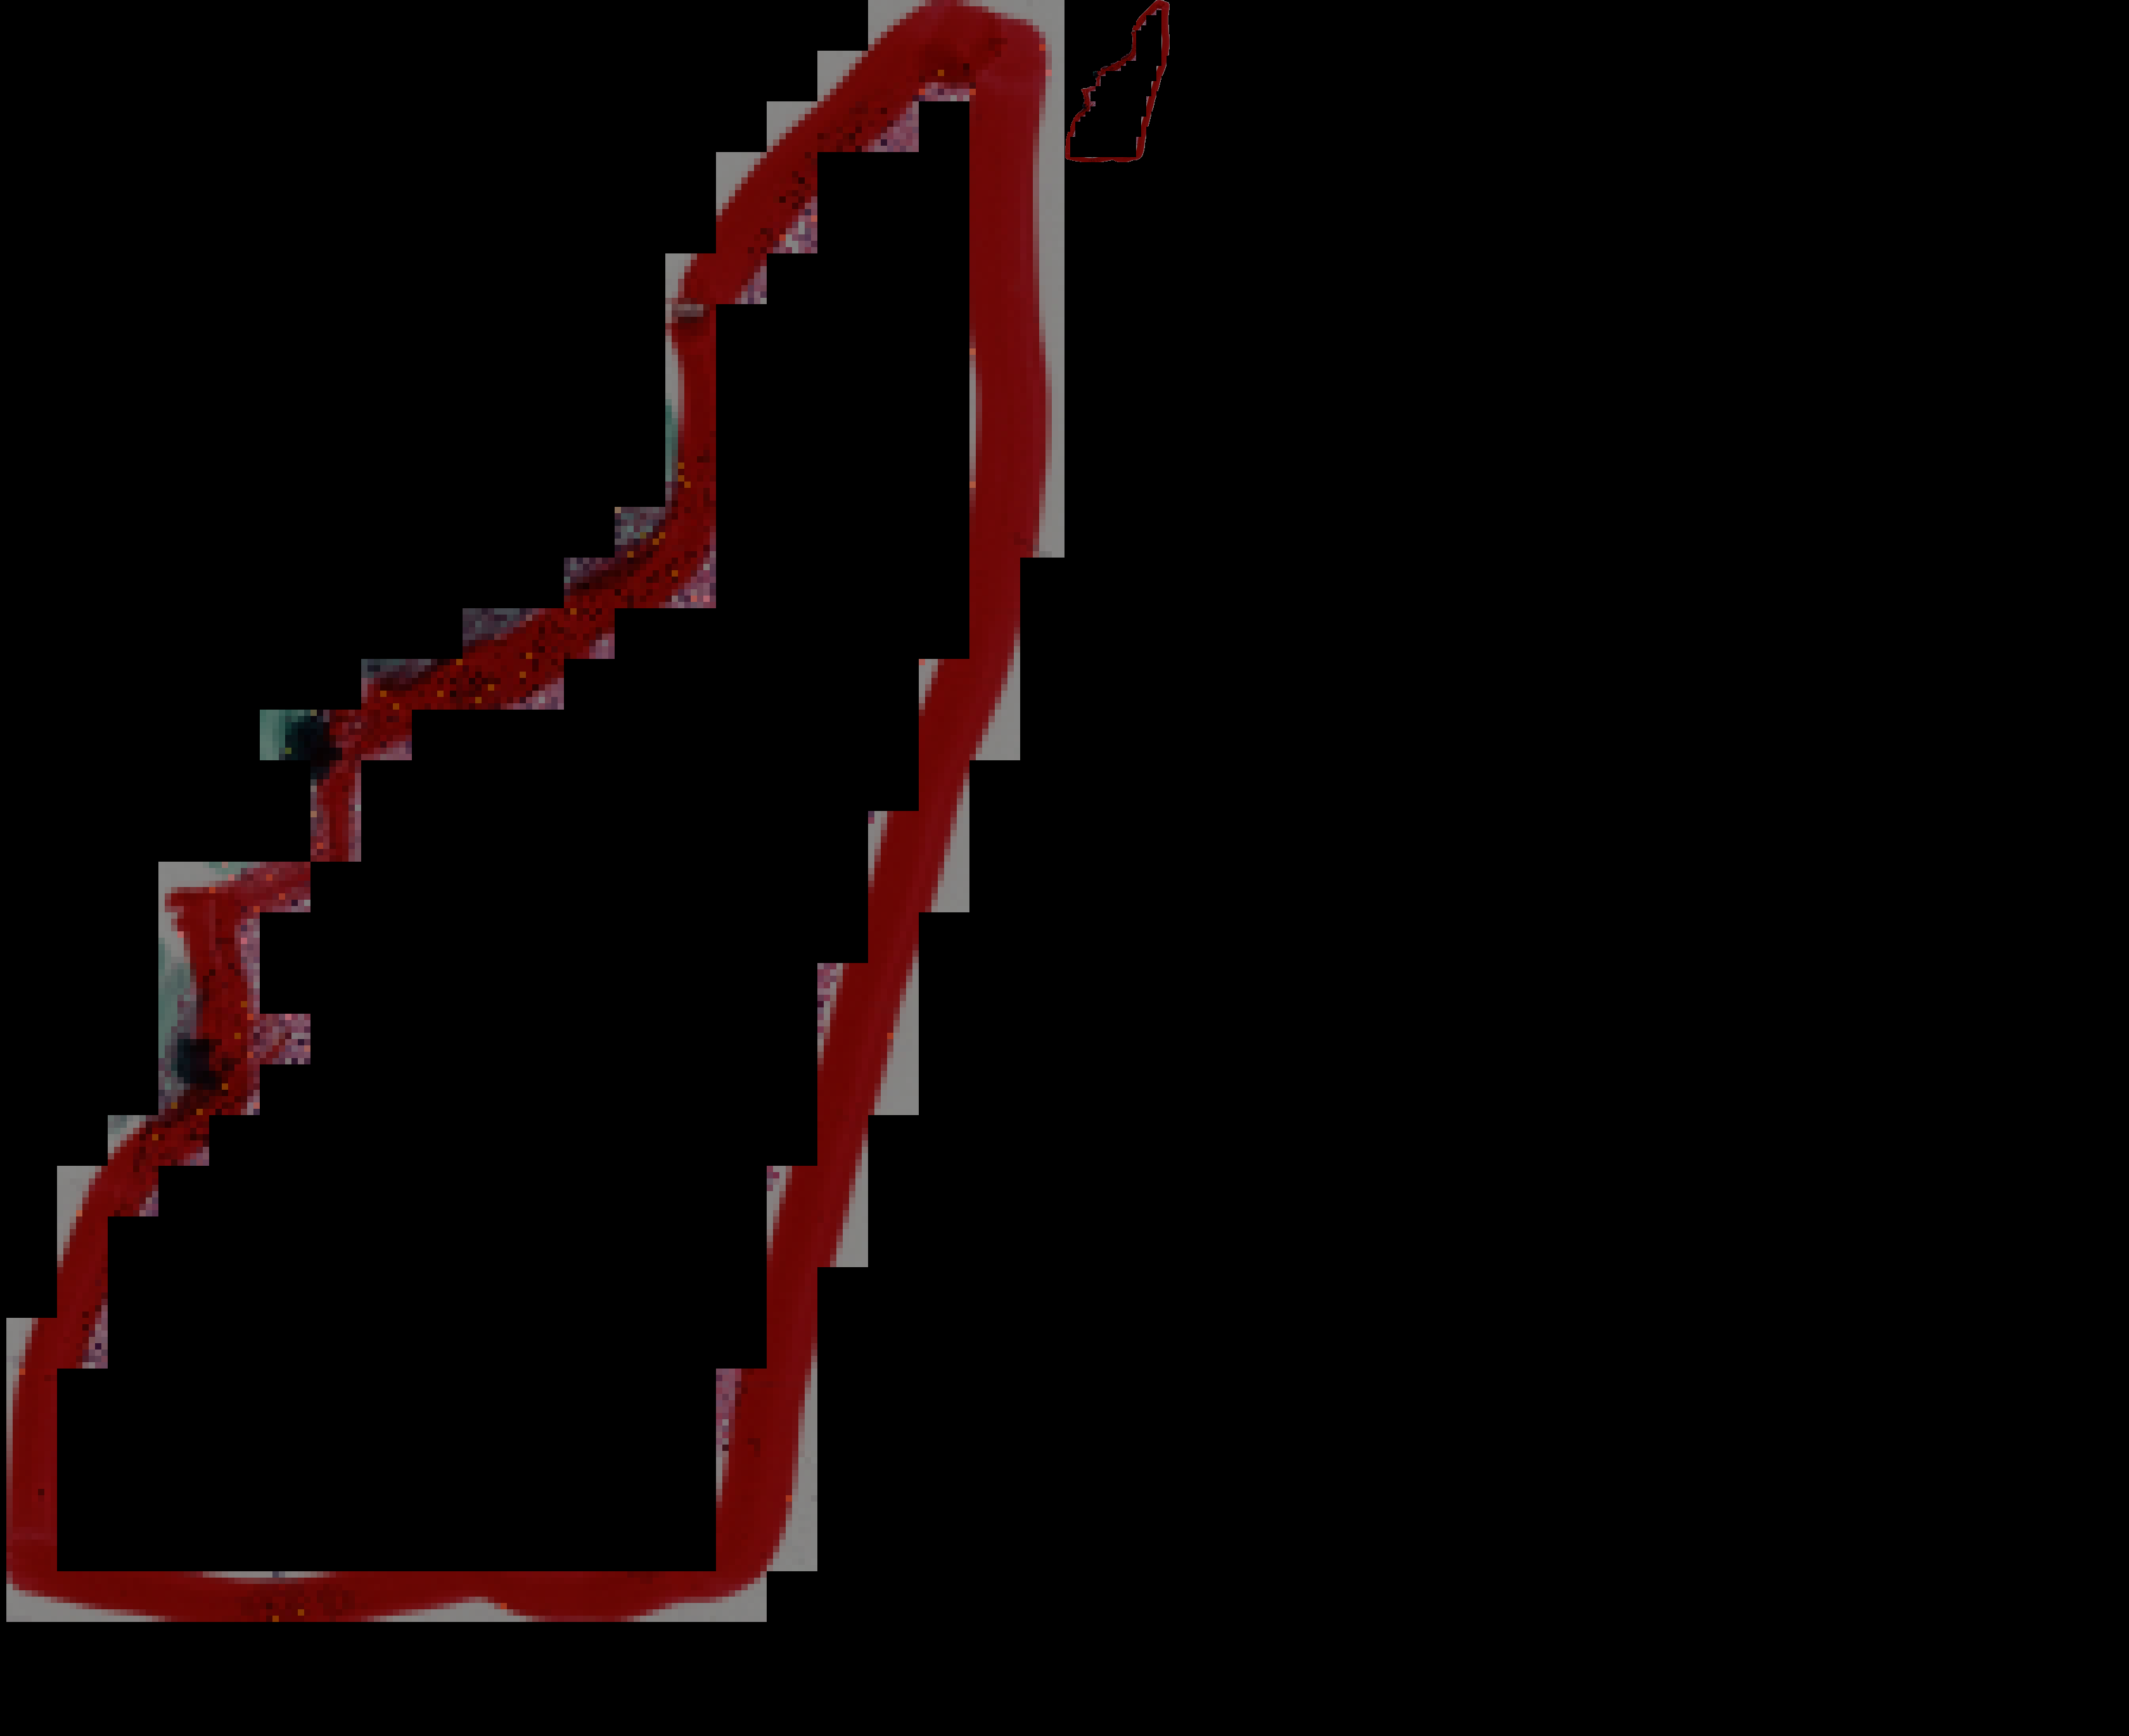

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_TCGA/TCGA-FC-7961-01Z-00-DX1.9a513f3d-b401-4450-8486-ee04751da4e8.png
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-G9-A9S7-01Z-00-DX1.E46D2A59-1B23-4841-B327-C9AAE176AD2D.png 
slide /workspace/data/TCGA/patches/TCGA-G9-A9S7-01Z-00-DX1.E46D2A59-1B23-4841-B327-C9AAE176AD2D.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 4.


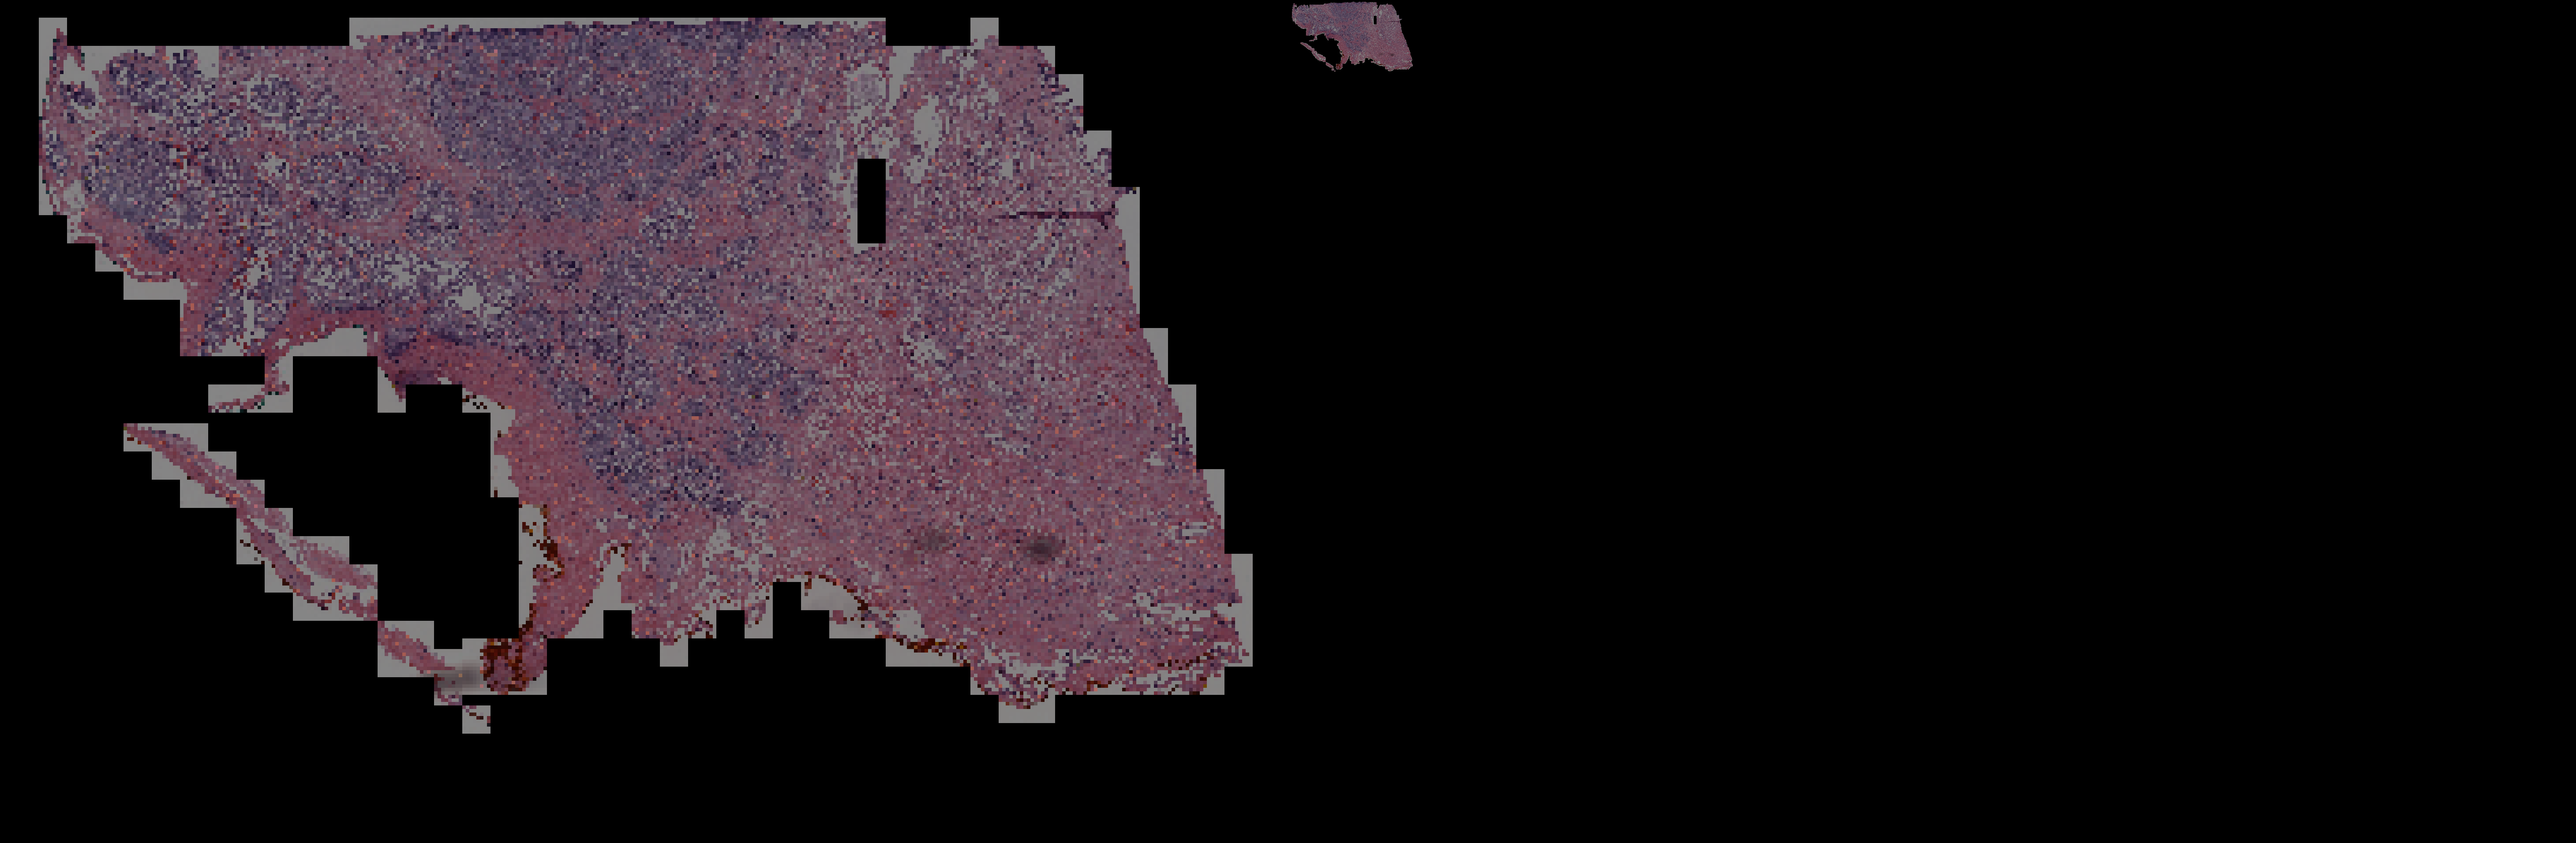

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_TCGA/TCGA-G9-A9S7-01Z-00-DX1.E46D2A59-1B23-4841-B327-C9AAE176AD2D.png
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-HC-7077-01Z-00-DX1.18652ead-c43f-41bd-aefd-5364bc4d236e.png 
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-HC-7231-01Z-00-DX1.0850ecf9-5d71-48b3-b147-716bd792e862.png 
 Cargando WSI desde: /workspace/data/TCGA/stitches/TCGA-HC-7819-01Z-00-DX1.9208cfe7-825f-4535-959c-ca470b61b562.png 


In [7]:
import os 
#urrent_dir  = os.path.abspath(os.getcwd()) # Directorio actual
#sys.path.append(os.path.dirname(current_dir))
from utils.heatmap_utils import gt_building, build_heatmap_binary,heatmap_building,  overlay_heatmap_on_image, draw_gt_patches, overlay_inside_green_line
test_outputs = test_outputs.head(20)
dataset = 'TCGA'
factor = 1

mask_folder= '/workspace/data/TCGA/stitches' #"/workspace/data/annotation_masks_SICAP" #'/workspace/data/TCGA/stitches'
folder_original_imgs = '/workspace/data/TCGA/stitches' #'/workspace/data/slides_filter'
green_folder = '/workspace/data/TCGA/masks'  #'/workspace/data/features_SICAP/masks'#'/workspace/data/TCGA/masks' 

for index, row in test_outputs.iterrows():

    slide_id = row['slide_id']
     # Cargar la WSI original 
    slide_id = slide_id.replace('.h5','')+ '.png'  #'.jpg'  # Ajustar extensión si es necesario
    file_name = slide_id.split('/')[-1]
    wsi_path = os.path.join(folder_original_imgs,file_name)
    print(f" Cargando WSI desde: {wsi_path} ")
    
    try: 
        orig, green, h, w = gt_building(wsi_path, green_folder, dataset= dataset, file_name=slide_id,factor = factor )
    except:
        continue
    mask, w_mask = build_heatmap_binary(coords = row['coords'], weights=row['weights'],scores = row['scores'],height = h, width=w, patch_size=512, scale_factor=factor)
   
    print('slide',row['slide_id'])

    #pred_primary, pred_secondary = select_gleason_grades_from_batch_proportions(proportions=row['wsi_logits'], min_presence_thresh=0.05, secondary_ratio_thresh=0.5)
    pred_primary, pred_secondary = row['wsi_logits'][0], row['wsi_logits'][1]
    if pred_primary == pred_secondary:
        grades = [pred_primary]
    else:
        grades = [pred_primary, pred_secondary]
    labels_dic = {0: "NC", 1: "Grade 3", 2: "Grade 4", 3: "Grade 5"}
    pred_primary = labels_dic.get(pred_primary.item())
    pred_secondary = labels_dic.get(pred_secondary.item())
    print(f" Scores de la slide: Grado Primario = {pred_primary} & Grado Secundario = {pred_secondary}.")
    # Imagen acumuladora (RGB)
    heatmap = heatmap_building(h,w, mask, w_mask, grades, factor = factor,slide_id = slide_id )
    
    #Crear overlay heatmap sobre la imagen
    overlay = overlay_heatmap_on_image(orig, heatmap)
    overlay_green = overlay_inside_green_line(green,overlay,green_thresh=(150, 100, 100))

    # Dibujar parches GT en la imagen real (lado izquierdo)
    orig_with_gt = draw_gt_patches(orig.copy(), file_name, mask_folder)

    # Crear imagen lado a lado
    w2, h2 = orig_with_gt.size
    w2 = w2*10
    h2 = h2*10
    orig_with_gt = orig_with_gt.resize((w2 ,h2), resample=Image.Resampling.NEAREST)
    
    canvas = Image.new("RGB",(w2*2, h2)) #(w2*2, h2))
    canvas.paste(orig_with_gt, (0, 0))
    canvas.paste(overlay_green, (w2, 0), overlay_green)

    canvas.show()
    out_name = row['slide_id'].replace('.h5', '.png')
    out_name = out_name.split('/')[-1]
    print(f"Guardando heatmap en : ... {os.path.join('/workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100',f'heatmaps_{dataset}',out_name )}")
    canvas.save(os.path.join('/workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100',f'heatmaps_{dataset}',out_name ), dpi=(300, 300))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# -----------------------------
# CONFIGURACIÓN
# -----------------------------

excel_gt = "/workspace/data/wsi_labels_changed_SICAP.xlsx"
df_pred = test_outputs.copy()

# -----------------------------
# CARGA DE DATOS
# -----------------------------

df_pred["image_id"] = (
    df_pred["slide_id"]
    .apply(lambda x: os.path.basename(x))   # 16B0003388_13.h5
    .str.split(".h5").str[0]    # 16B0003388_13
    .str.split("_").str[0]                  # 16B0003388
)
# GT
df_gt = pd.read_excel(excel_gt)
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =========================
# 1. Merge GT y predicciones
# =========================
df = df_gt.merge(
    df_pred,
    left_on="image_id",
    right_on="image_id",
    how="inner"
)

# =========================
# 2. Extraer predicciones
# =========================
# Primary y secondary desde wsi_logits
df["pred_primary"] = df["wsi_logits"].apply(lambda x: x[0].item())
df["pred_secondary"] = df["wsi_logits"].apply(lambda x: x[1].item())

# Gleason score como suma de logits
df["pred_gleason_score"] = df["wsi_logits"].apply(lambda x: sum(x).item())

# ------------------------------------------------------------------
# ⚠️ SI LOS LOGITS NO SON CLASES ENTERAS, discretiza aquí
# Ejemplo:
df["pred_primary"] = df["pred_primary"].round().astype(int)
df["pred_secondary"] = df["pred_secondary"].round().astype(int)
df["pred_gleason_score"] = df["pred_gleason_score"].round().astype(int)
# ------------------------------------------------------------------

# =========================
# 3. Matrices de confusión
# =========================

# 1️⃣ Gleason score vs suma de wsi_logits
cm_score = confusion_matrix(
    df["gleason_score"],
    df["pred_gleason_score"], labels=[6,7,8,9,10]
)

# 2️⃣ Gleason primary vs primer logit
cm_primary = confusion_matrix(
    df["gleason_primary"],
    df["pred_primary"], labels= [0,1,2,3]
)

# 3️⃣ Gleason secondary vs segundo logit
cm_secondary = confusion_matrix(
    df["gleason_secondary"],
    df["pred_secondary"], labels= [0,1,2,3]
)

# =========================
# 4. Visualización
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(cm_score).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Gleason score vs sum(wsi_logits)")

ConfusionMatrixDisplay(cm_primary).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Gleason primary vs wsi_logits[0]")

ConfusionMatrixDisplay(cm_secondary).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Gleason secondary vs wsi_logits[1]")

plt.tight_layout()
plt.show()
